In [1]:
import cv2 as cv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import skimage as ski

import numpy.ma as ma
# import cupy as cp

import scipy as sp

import statistics as st

from itertools import cycle

# from sklearn.preprocessing import minmax_scale
import pandas as pd

from scipy import ndimage as ndi
from skimage.feature import peak_local_max

In [2]:
matplotlib.rcParams['figure.dpi'] = 200
matplotlib.rcParams['figure.figsize'] = [6.4, 4.9]

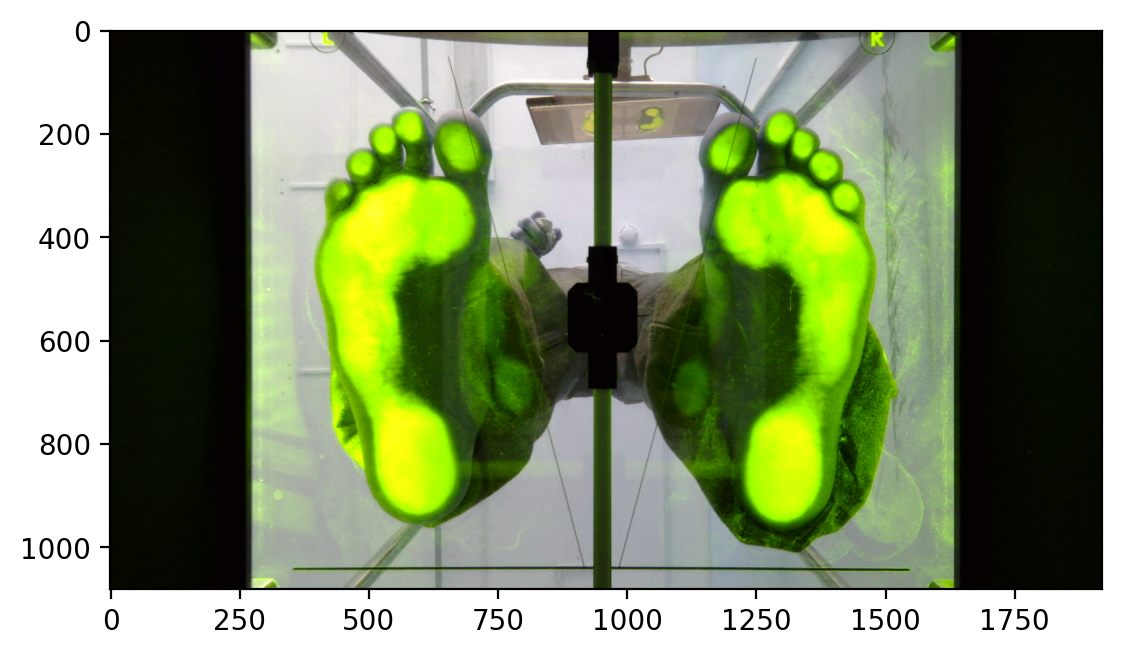

In [73]:
image = cv.imread("./плантограммы/Img (copy 4).png")

plt.imshow(image)

In [74]:
def split_foot(image):
    leftPad = 280
    rightPad = 1920 - 1630
    yPad = 50
    assert image.shape == (1080, 1920, 3)
    return image[yPad:,leftPad:880,:], image[yPad:,1025:-rightPad,:]


(1030, 600, 3) (1030, 605, 3)


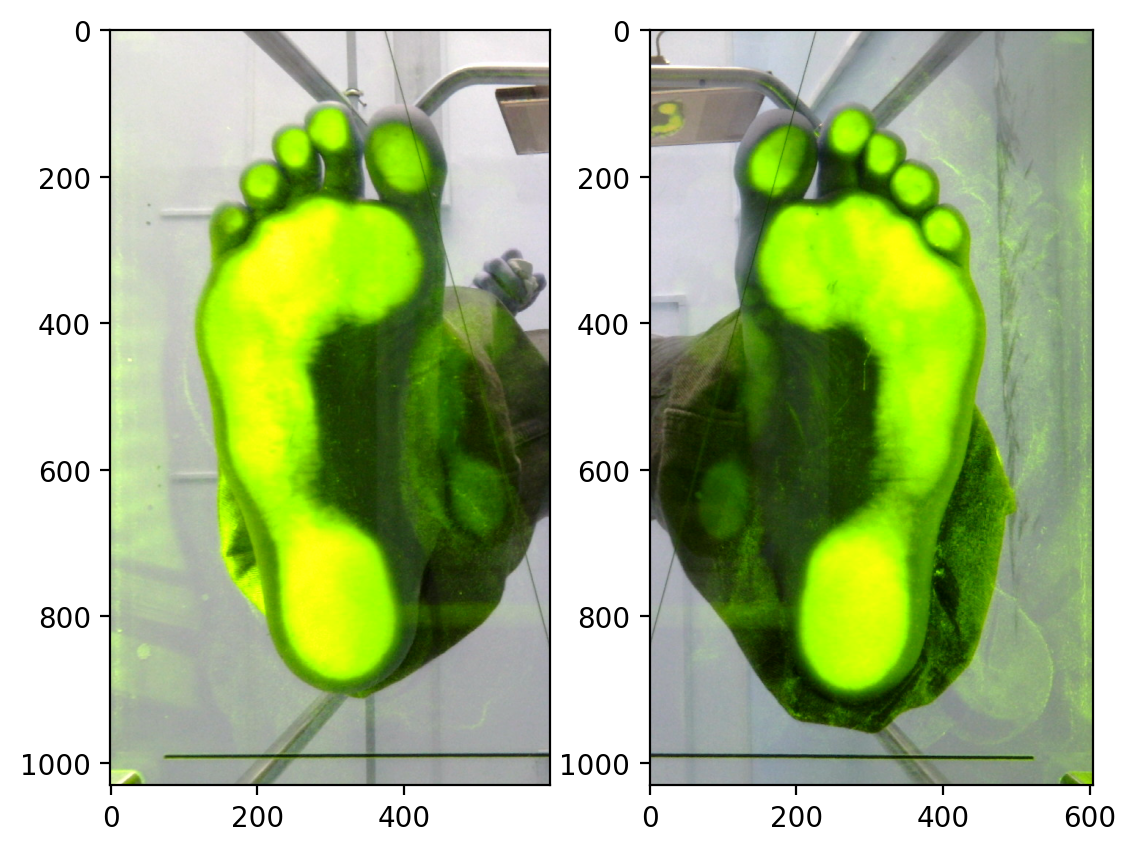

In [75]:
footL, footR = split_foot(image)
fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(footL)
ax2.imshow(footR)
# ax1.grid(which='major')
# ax1.set_yticks(np.linspace(0, 1100, 65), )
print(footL.shape, footR.shape)

In [89]:
hsv = cv.cvtColor(footL, cv.COLOR_RGB2HSV)
hsv

array([[[ 38,  13, 231],
        [ 38,  13, 230],
        [ 37,  14, 231],
        ...,
        [140,   3, 237],
        [140,   3, 236],
        [140,   3, 236]],

       [[ 38,  13, 231],
        [ 38,  13, 231],
        [ 37,  14, 231],
        ...,
        [140,   3, 236],
        [140,   3, 236],
        [140,   3, 236]],

       [[ 38,  13, 231],
        [ 38,  13, 231],
        [ 38,  13, 231],
        ...,
        [140,   3, 235],
        [140,   3, 234],
        [140,   3, 234]],

       ...,

       [[ 41,  81, 240],
        [ 41,  80, 241],
        [ 41,  81, 242],
        ...,
        [ 98,   7, 156],
        [ 90,   8, 159],
        [ 90,   8, 160]],

       [[ 41,  82, 240],
        [ 41,  81, 241],
        [ 40,  84, 244],
        ...,
        [ 98,   6, 157],
        [ 98,   6, 159],
        [ 98,   6, 160]],

       [[ 41,  85, 241],
        [ 41,  84, 243],
        [ 39,  83, 244],
        ...,
        [ 98,   6, 159],
        [ 98,   6, 161],
        [ 98,   6, 161]]

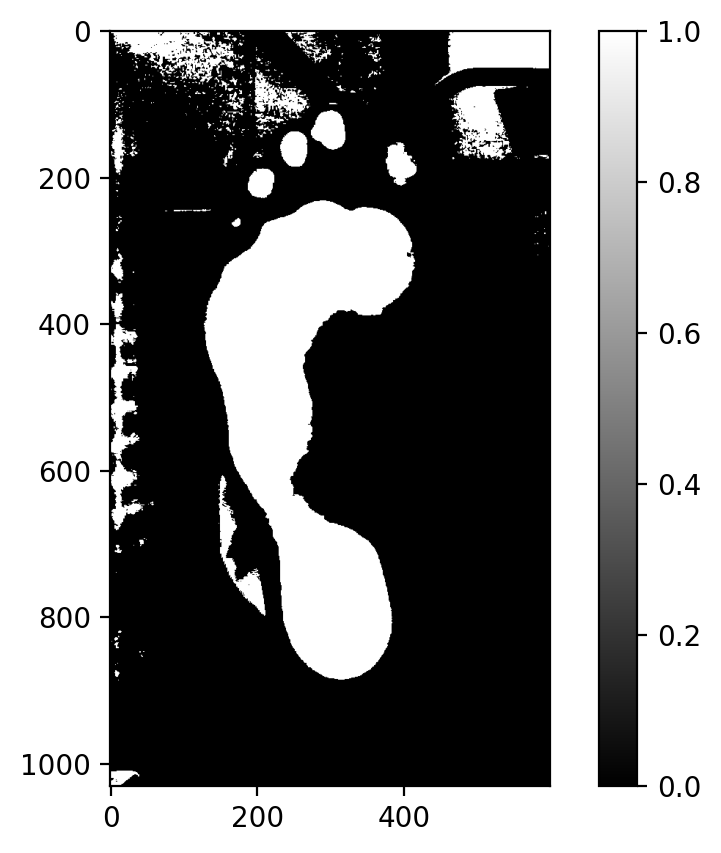

In [92]:
hsv = cv.cvtColor(footL, cv.COLOR_RGB2HSV)

V = hsv[...,2]
mask = V > 230
V[~mask] = 0 
plt.imshow(mask, 'gray')
plt.colorbar()

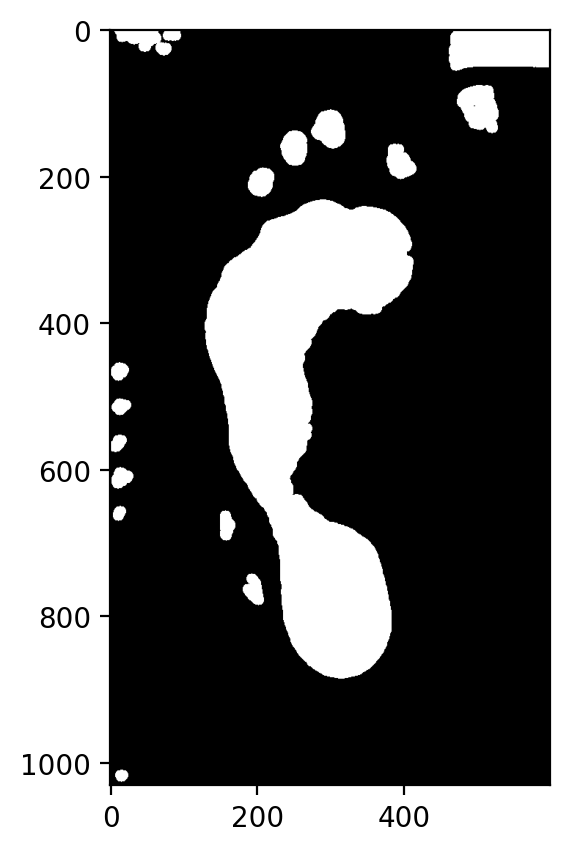

In [93]:
ksize = 15

kernelEllipse = cv.getStructuringElement(cv.MORPH_ELLIPSE,(ksize, ksize))
# kernelRect = cv.getStructuringElement(cv.MORPH_RECT,(ksize, ksize))

openingEllipse1 = cv.morphologyEx(np.asarray(mask, np.uint8), cv.MORPH_OPEN, kernelEllipse)

plt.imshow(openingEllipse1, 'gray')

(1030, 600)


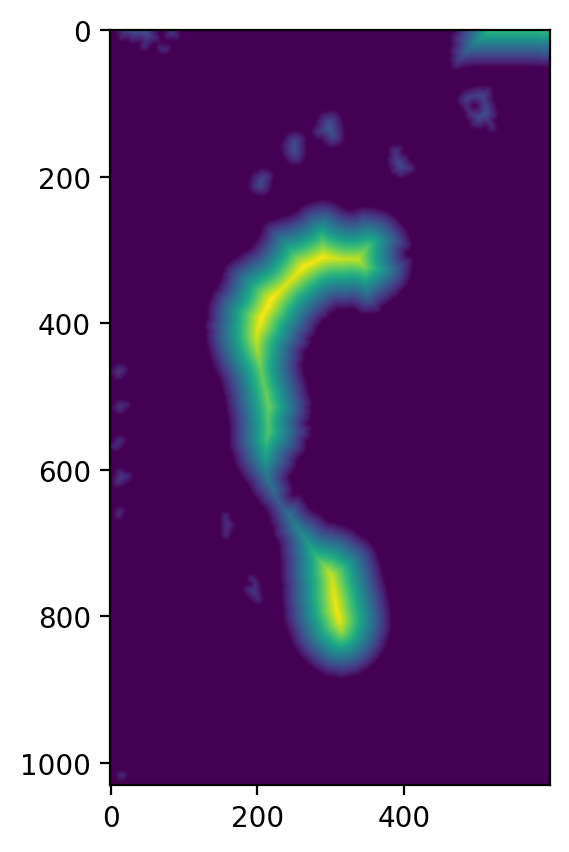

In [123]:
imageDT = sp.ndimage.distance_transform_edt(openingEllipse1)
print(dt.shape)
plt.imshow(dt)

In [94]:
# hsv[...,0]
H = hsv[...,0]
hsv

array([[[ 38,  13, 231],
        [ 38,  13,   0],
        [ 37,  14, 231],
        ...,
        [140,   3, 237],
        [140,   3, 236],
        [140,   3, 236]],

       [[ 38,  13, 231],
        [ 38,  13, 231],
        [ 37,  14, 231],
        ...,
        [140,   3, 236],
        [140,   3, 236],
        [140,   3, 236]],

       [[ 38,  13, 231],
        [ 38,  13, 231],
        [ 38,  13, 231],
        ...,
        [140,   3, 235],
        [140,   3, 234],
        [140,   3, 234]],

       ...,

       [[ 41,  81, 240],
        [ 41,  80, 241],
        [ 41,  81, 242],
        ...,
        [ 98,   7,   0],
        [ 90,   8,   0],
        [ 90,   8,   0]],

       [[ 41,  82, 240],
        [ 41,  81, 241],
        [ 40,  84, 244],
        ...,
        [ 98,   6,   0],
        [ 98,   6,   0],
        [ 98,   6,   0]],

       [[ 41,  85, 241],
        [ 41,  84, 243],
        [ 39,  83, 244],
        ...,
        [ 98,   6,   0],
        [ 98,   6,   0],
        [ 98,   6,   0]]

In [221]:
# X = hsv[...,0:3]
# hsv = cv.cvtColor(footL, cv.COLOR_RGB2HSV)

# X = hsv
X = cv.cvtColor(footL, cv.COLOR_RGB2Lab)

# X = footL

X = X[:,:,[0,2]]
# X = np.expand_dims(X, 2)

# X = np.expand_dims(X, axis=2)
# X[:,:,np.newaxis] = imageDT
# print(np.atleast_3d(X).shape)
# X[] = imageDT
# print(X)
# print(np.expand_dims(imageDT, 2).shape)
# print(np.concatenate([X, np.expand_dims(imageDT, 2)], axis=-1).shape)
# X = np.concatenate([X, np.expand_dims(imageDT, 2)], axis=-1)
fitX = X.reshape(X.shape[0] * X.shape[1], X.shape[2])
fitX


array([[233, 133],
       [232, 133],
       [233, 134],
       ...,
       [166, 127],
       [168, 127],
       [168, 127]], shape=(618000, 2), dtype=uint8)

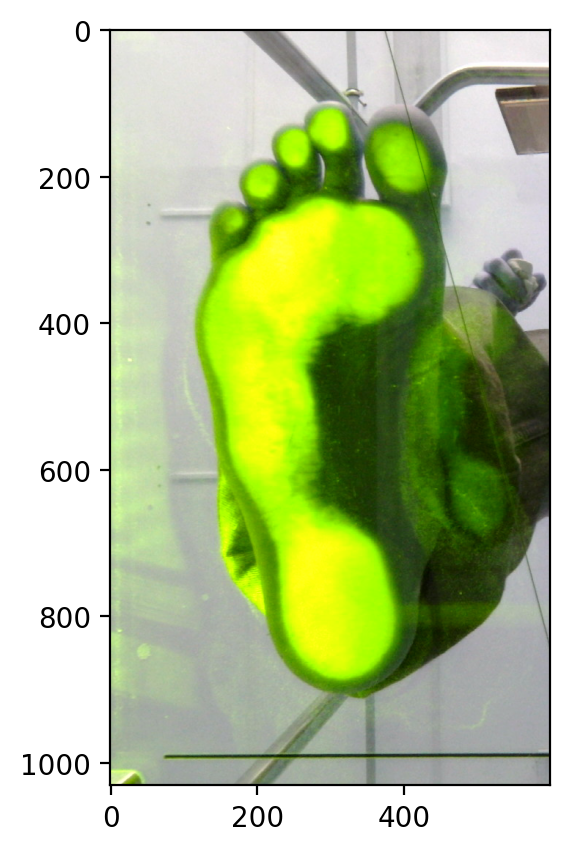

In [214]:
plt.imshow(X)

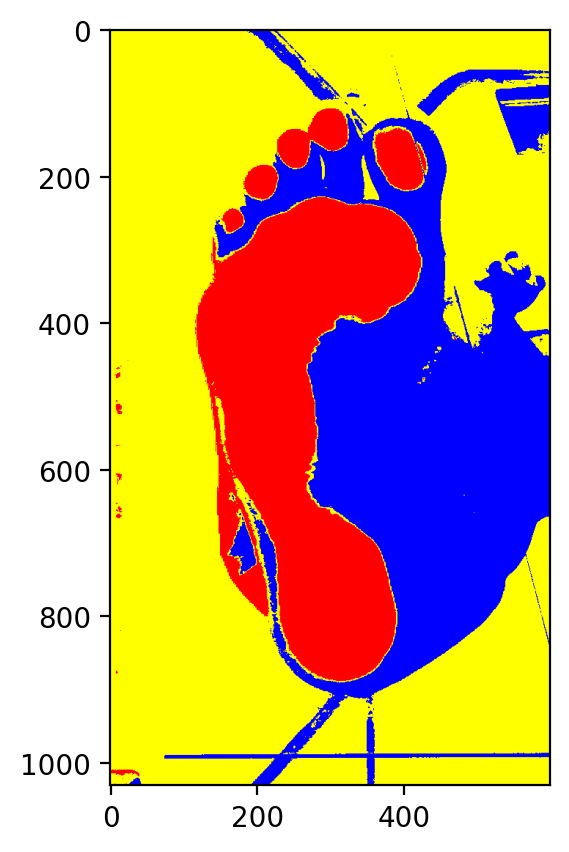

In [224]:
from sklearn.cluster import KMeans

n = 3
kmeans = KMeans(max_iter=300,n_clusters=n, random_state=0, n_init="auto").fit(fitX)

# kmeans.

clustered = kmeans.cluster_centers_[kmeans.labels_]
labels = kmeans.labels_

labels = labels.reshape(hsv.shape[0], hsv.shape[1])

labels = labels + 1

plt.imshow(ski.color.label2rgb(labels))
# for n in range(n):
#     image_cluster = []
#     for i in range(len(labels)):
#         if(labels[i]) == n:
#             image_cluster.append(float(clustered[i]))
#         else:
#             image_cluster.append(1)
#     if(n==1):
#         image_fix= np.array(image_cluster).reshape(grayscale.shape)
#     reshape_clustered = np.array(image_cluster).reshape(grayscale.shape)
#     plt.imshow(reshape_clustered, cmap=plt.get_cmap("gray"),vmin=0, vmax=1)
#     plt.show()
# plt.imshow(ski.color.label2rgb(kmeans.labels_))

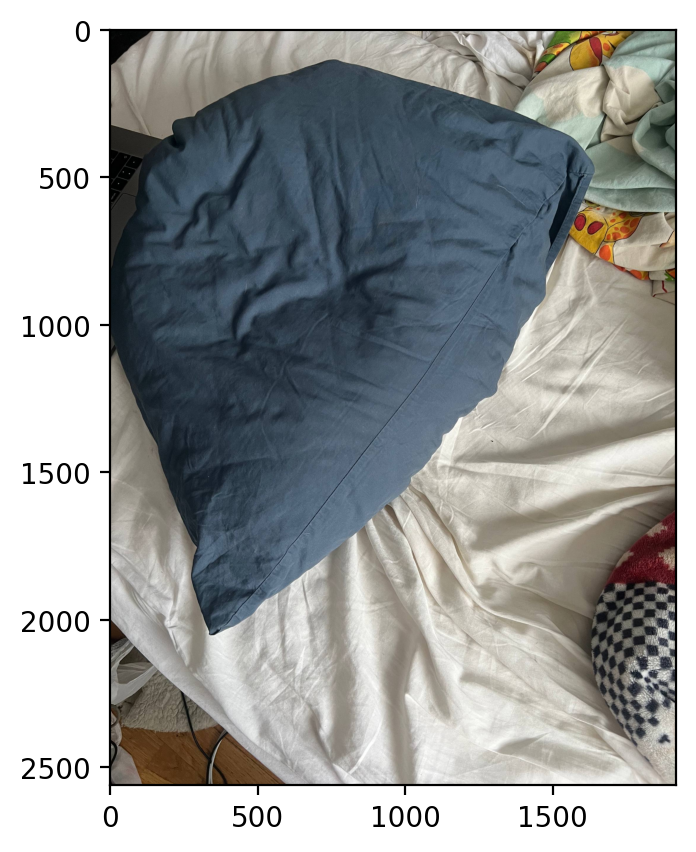

In [227]:
img = cv.imread('./images/photo_2026-01-30_12-10-43.jpg', cv.IMREAD_COLOR_RGB)

plt.imshow(img)

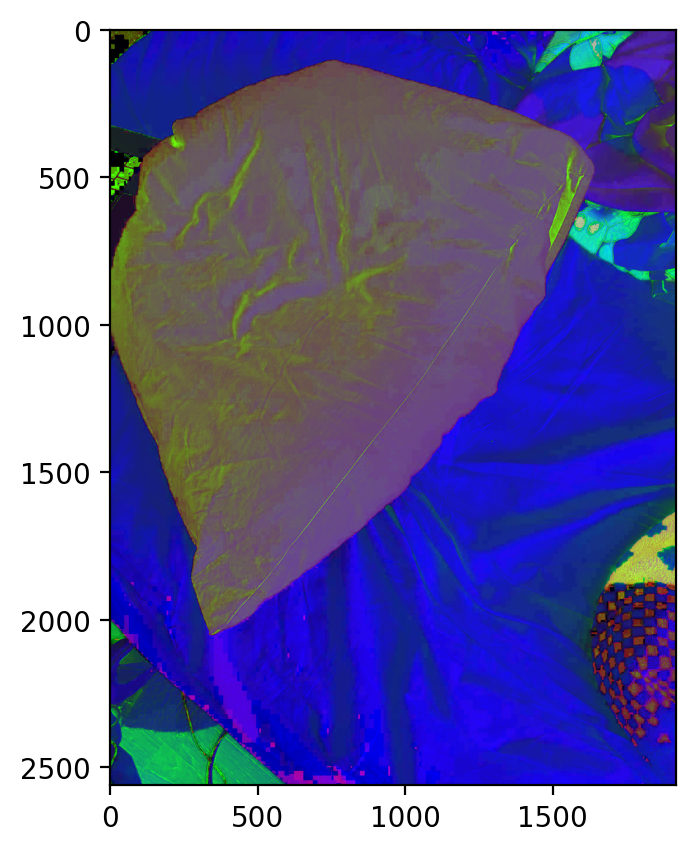

In [228]:
hsv = cv.cvtColor(img, cv.COLOR_RGB2HSV)

plt.imshow(hsv)

In [248]:
# X = hsv[:,:,[1,2]]

X = img

fitX = X.reshape(X.shape[0] * X.shape[1], X.shape[2])
fitX

array([[  0,   1,   0],
       [  4,   6,   5],
       [  8,  10,   9],
       ...,
       [193, 189, 178],
       [202, 198, 187],
       [208, 204, 193]], shape=(4915200, 3), dtype=uint8)

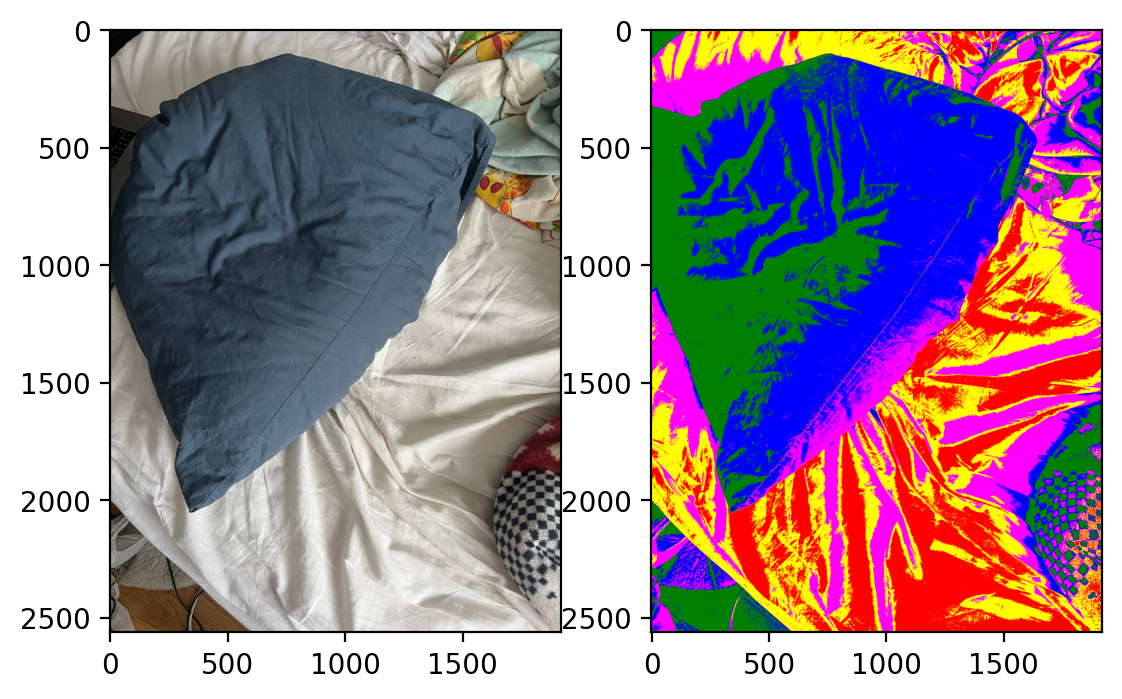

In [250]:

n = 5
kmeans = KMeans(max_iter=300,n_clusters=n, random_state=0, n_init="auto").fit(fitX)

# kmeans.

clustered = kmeans.cluster_centers_[kmeans.labels_]
labels = kmeans.labels_

labels = labels.reshape(hsv.shape[0], hsv.shape[1])

labels = labels + 1

fig,axs = plt.subplots(1, 2)

axs[0].imshow(img)
axs[1].imshow(ski.color.label2rgb(labels))